<a href="https://colab.research.google.com/github/jhlopesalves/eda_humanidades/blob/main/encontro_12/enc_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Encontro 12: Análise linguística de um corpus jornalístico

Neste encontro, reuniremos procedimentos desenvolvidos ao longo do curso em uma
análise de notícias da **Folha de S.Paulo**. A pergunta que orientará o trabalho é:
**como as seções do jornal se diferenciam na distribuição de palavras e em
características linguísticas de suas matérias?**

Começaremos pela estrutura do arquivo e pelo comprimento dos textos. Em seguida,
examinaremos a frequência e a dispersão de cinco palavras, usaremos o spaCy para
produzir anotações linguísticas e calcularemos medidas por matéria. Essas medidas
servirão à comparação entre seções por testes de permutação e a uma visualização
com análise de componentes principais.


## 1. Fonte e carregamento dos dados

Usaremos o conjunto
[`emdemor/news-of-the-brazilian-newspaper`](https://huggingface.co/datasets/emdemor/news-of-the-brazilian-newspaper),
disponível no Hugging Face. A página do conjunto atribui a coleta original a
Marlesson Santana e fornece os links para o projeto de coleta e a versão
publicada no Kaggle.

Leremos a versão em **Parquet**, um formato que organiza os dados por colunas e
que o pandas pode carregar diretamente de uma URL. A biblioteca `pyarrow`,
instalada a seguir, fornece o suporte a esse formato.


In [1]:
!pip install -q pyarrow

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [3]:
rng = np.random.default_rng(42)

### 1.1 Leitura do arquivo e nomes das colunas

O arquivo usa nomes de colunas em inglês. Vamos adotar os equivalentes em
português para os campos que aparecerão com frequência na análise: `title`
passará a `titulo`; `text`, a `texto`; `date`, a `data`; `category`, a `categoria`;
e `subcategory`, a `subcategoria`.

O método `rename()` modifica os rótulos das colunas, preservando os valores dos
registros. Depois da leitura, `head()` exibirá as primeiras linhas para
conferirmos a estrutura do DataFrame.


In [4]:
url = (
    "https://huggingface.co/datasets/"
    "emdemor/news-of-the-brazilian-newspaper/"
    "resolve/refs%2Fconvert%2Fparquet/"
    "default/train/0000.parquet"
)

noticias_df = (
    pd.read_parquet(url)
    .rename(
        columns={
            "title": "titulo",
            "text": "texto",
            "date": "data",
            "category": "categoria",
            "subcategory": "subcategoria",
        }
    )
)

noticias_df.head()

,titulo,texto,data,categoria,subcategoria,link
0,"Lula diz que está 'lascado', mas que ainda tem...",Com a possibilidade de uma condenação impedir ...,2017-09-10,poder,None,http://www1.folha.uol.com.br/poder/2017/10/192...
1,"'Decidi ser escrava das mulheres que sofrem', ...","Para Oumou Sangaré, cantora e ativista malines...",2017-09-10,ilustrada,None,http://www1.folha.uol.com.br/ilustrada/2017/10...
2,Três reportagens da Folha ganham Prêmio Petrob...,Três reportagens da Folha foram vencedoras do ...,2017-09-10,poder,None,http://www1.folha.uol.com.br/poder/2017/10/192...
3,Filme 'Star Wars: Os Últimos Jedi' ganha trail...,A Disney divulgou na noite desta segunda-feira...,2017-09-10,ilustrada,None,http://www1.folha.uol.com.br/ilustrada/2017/10...
4,CBSS inicia acordos com fintechs e quer 30% do...,"O CBSS, banco da holding Elopar dos sócios Bra...",2017-09-10,mercado,None,http://www1.folha.uol.com.br/mercado/2017/10/1...


### 1.2 Estrutura e valores ausentes

Cada linha corresponde a um registro de matéria, acompanhado de título, texto,
data, seção, subcategoria e link. Essa será nossa unidade inicial de observação.

O método `info()` apresenta o número de linhas, as colunas, seus tipos e a
quantidade de valores preenchidos. A inspeção mostra **167.053
registros**, dos quais **166.288** têm o campo `texto` preenchido. A diferença
de 765 registros será considerada na seleção do corpus.


In [5]:
noticias_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167053 entries, 0 to 167052
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   titulo        167053 non-null  object
 1   texto         166288 non-null  object
 2   data          167053 non-null  object
 3   categoria     167053 non-null  object
 4   subcategoria  29635 non-null   object
 5   link          167053 non-null  object
dtypes: object(6)
memory usage: 7.6+ MB


## 2. Exploração do corpus

### 2.1 Comprimento das matérias

Vamos representar o comprimento de cada matéria pelo número de segmentos obtidos
com `str.split()`. Com sua configuração padrão, esse método separa a string nos
espaços em branco; `str.len()` conta os elementos da lista resultante.

Chamaremos essa medida de `n_palavras`. Ela fornece uma aproximação operacional
do tamanho do texto, dependente desse critério de segmentação. Mais adiante,
usaremos outros critérios para contar tokens e precisaremos distinguir suas
unidades.


In [6]:
# 1. .str.split() divide cada texto nos espaços em branco, gerando uma lista de palavras por linha;
# 2. .str.len() conta quantos elementos (palavras) existem dentro de cada lista.
noticias_df["n_palavras"] = noticias_df["texto"].str.split().str.len()

# Calcula as estatísticas descritivas (média, desvio-padrão, quartis e extremos) da nova coluna.
noticias_df["n_palavras"].describe()


,n_palavras
count,166288.000000
mean,446.697573
std,317.289028
min,1.000000
25%,251.000000
50%,394.000000
75%,565.000000
max,10434.000000


### 2.2 Número de registros por seção

O campo `categoria` identifica a seção editorial de cada registro.
`value_counts()` contará quantas linhas pertencem a cada categoria, e `head(10)`
exibirá as dez mais frequentes.

Essa contagem descreve a composição do arquivo carregado. Como ainda estamos
usando `noticias_df`, ela inclui registros com o campo `texto` ausente. A
quantidade de textos disponíveis será conferida novamente após a filtragem.


In [7]:
noticias_df["categoria"].value_counts().head(10)

,count
categoria,
poder,22022
colunas,21622
mercado,20970
esporte,19730
mundo,17130
cotidiano,16967
ilustrada,16345
opiniao,4525
paineldoleitor,4011


### 2.3 Mediana do comprimento por seção

A mediana divide os comprimentos ordenados em duas metades e oferece um resumo
do tamanho típico das matérias. Sua menor sensibilidade a valores extremos é
útil diante da amplitude observada em `n_palavras`.

Vamos agrupar os registros por seção, calcular a mediana e ordenar o resultado.
No resultado abaixo, `esporte` apresenta mediana de 299 segmentos,
enquanto `ilustrissima` apresenta 846. Essa diferença descreve o centro de cada
grupo; a comparação das distribuições mostrará também sua variabilidade.

As categorias com resultado `NaN` exigem atenção à disponibilidade de textos:
esse valor indica ausência de uma mediana calculável naquele grupo.


In [8]:
# Agrupa o DataFrame por seção, seleciona a coluna com a contagem de palavras,
# calcula a mediana de cada grupo e ordena da menor para a maior.
(
    noticias_df
    .groupby("categoria")["n_palavras"]
    .median()
    .sort_values()
)


,n_palavras
categoria,
bichos,1.0
infograficos,15.5
banco-de-dados,97.5
tv,99.0
euronews,175.5
paineldoleitor,176.0
multimidia,182.0
folhinha,187.0
ombudsman,217.0


### 2.4 Seleção das seções e dos textos disponíveis

O restante da análise acompanhará sete categorias: `poder`, `mercado`, `esporte`,
`mundo`, `ilustrada`, `colunas` e `ilustrissima`. A seleção permite comparar
diferentes domínios do noticiário e conserva pelo menos 500 textos em cada
seção, quantidade que usaremos na etapa de anotação linguística.

Construiremos `corpus_df` em três operações: `dropna()` selecionará os registros
com texto preenchido; `query()` manterá as sete categorias; e `copy()` criará o
DataFrame no qual acrescentaremos as medidas. A contagem por categoria conferirá
o tamanho de cada grupo após o recorte.

As seções têm tamanhos bastante diferentes: `poder` reúne 22.022
textos e `ilustrissima`, 1.409. Essa composição influencia as medidas calculadas
para o corpus como um todo. Além disso, o preenchimento do campo `texto` é apenas
um critério de disponibilidade; a avaliação da integridade dos textos requer
inspeção de seu conteúdo.


In [9]:
categorias_selecionadas = [
    "poder",
    "mercado",
    "esporte",
    "mundo",
    "ilustrada",
    "colunas",
    "ilustrissima",
]

# 1. .dropna(subset=["texto"]): remove linhas onde a coluna 'texto' é nula (NaN/None);
# 2. .query(...): mantém apenas as linhas cuja categoria pertence à nossa lista (@ referencia a variável externa);
# 3. .copy(): cria uma cópia independente na memória, evitando avisos (SettingWithCopyWarning) ao criarmos novas colunas adiante.
corpus_df = (
    noticias_df
    .dropna(subset=["texto"])
    .query("categoria in @categorias_selecionadas")
    .copy()
)

# Verifica o total de matérias válidas restantes em cada uma das 7 seções.
corpus_df["categoria"].value_counts()


,count
categoria,
poder,22022
colunas,21619
mercado,20970
esporte,19730
mundo,17130
ilustrada,15617
ilustrissima,1409


### 2.5 Distribuição do comprimento por seção

O [**boxenplot**](https://seaborn.pydata.org/generated/seaborn.boxenplot.html) representa a distribuição por meio de caixas delimitadas por
quantis sucessivos. A linha central marca a mediana, e as caixas permitem
acompanhar a distribuição em direção às caudas. Esse detalhamento é útil para
comparar grupos com muitas observações.

Ao ler o gráfico, observaremos a posição das medianas, a extensão das caixas e
a assimetria dos comprimentos em cada seção. Textos de uma mesma categoria podem
apresentar ampla variação, mesmo quando a mediana difere daquela de outra seção.

O argumento `showfliers=False` oculta os pontos extremos que seriam desenhados
além das caixas. Essas observações continuam no DataFrame e nos cálculos. O
dicionário `paleta_categorias` associa uma cor a cada seção e será reutilizado
na visualização final.


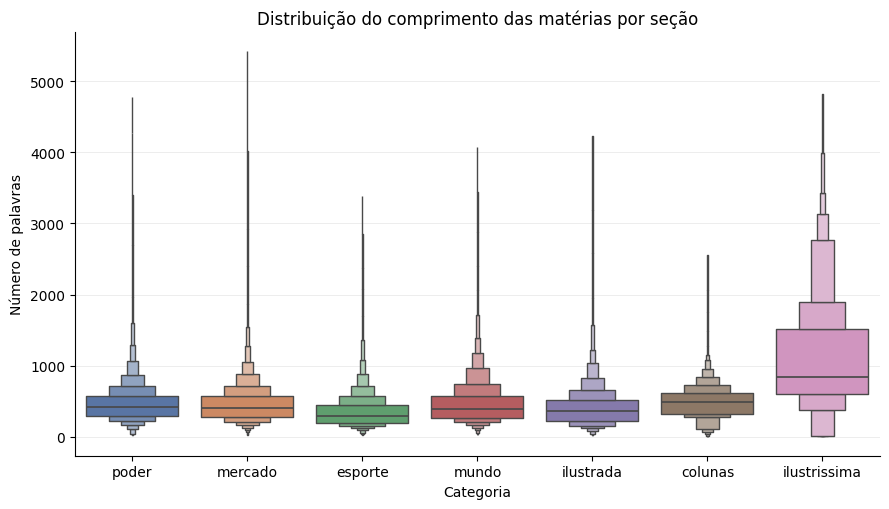

In [10]:
# Cria um dicionário que associa cada seção a uma cor fixa da paleta "deep".
# A função zip() pareia os nomes das categorias com as cores geradas pelo Seaborn,
# garantindo que cada seção mantenha exatamente a mesma cor em todos os gráficos da aula.
paleta_categorias = dict(
    zip(
        categorias_selecionadas,
        sns.color_palette("deep", n_colors=len(categorias_selecionadas)),
    )
)

# Cria a figura e os eixos (ax) definindo o tamanho da imagem em polegadas (largura, altura).
fig, ax = plt.subplots(figsize=(9, 5.2))

sns.boxenplot(
    data=corpus_df,
    x="categoria",
    y="n_palavras",
    order=categorias_selecionadas,
    hue="categoria",
    palette=paleta_categorias,
    linewidth=1,
    showfliers=False, # Oculta os pontos extremos (outliers) apenas na visualização
    legend=False, # Dispensa a legenda lateral (os nomes já estão no eixo x)
    ax=ax,
)

ax.set(
    title="Distribuição do comprimento das matérias por seção",
    xlabel="Categoria",
    ylabel="Número de palavras",
)

# Adiciona linhas de grade horizontais discretas ao fundo para facilitar a leitura dos valores.
ax.grid(axis="y", alpha=0.4, linewidth=0.4)
ax.set_axisbelow(True)  # Garante que a grade fique atrás das caixas do gráfico

sns.despine()
plt.tight_layout()
plt.show()


### 2.6 Resumo numérico das distribuições

Vamos complementar o boxenplot com `describe()` aplicado a cada seção. A saída
reúne contagem, média, desvio-padrão, mínimo, quartis e máximo de `n_palavras`.

A leitura conjunta da média, da mediana e dos quartis ajuda a caracterizar a
assimetria. Em `ilustrissima`, por exemplo, o resumo apresenta média de
aproximadamente 1.127 segmentos e mediana de 846. A extensão da cauda superior
ajuda a compreender a distância entre esses dois resumos.


In [11]:
# Agrupa o corpus analítico pelas 7 seções e calcula o resumo estatístico
# completo da coluna 'n_palavras' para cada editoria.
(
    corpus_df
    .groupby("categoria")["n_palavras"]
    .describe()
)


,count,mean,std,min,25%,50%,75%,max
categoria,,,,,,,,
colunas,21619.0,485.131320,242.238135,5.0,316.0,494.0,610.5,9833.0
esporte,19730.0,355.839027,257.461513,12.0,201.0,299.0,446.0,9636.0
ilustrada,15617.0,413.629891,305.906241,2.0,220.0,369.0,522.0,6265.0
ilustrissima,1409.0,1127.058907,869.226381,1.0,606.0,846.0,1515.0,8030.0
mercado,20970.0,461.160849,305.797282,14.0,276.0,410.0,569.0,10434.0
mundo,17130.0,465.741331,315.631378,33.0,266.0,395.0,569.0,6361.0
poder,22022.0,469.495777,301.367047,6.0,296.0,423.0,575.0,8629.0


## 3. Frequência e dispersão lexical

### 3.1 Ocorrências de palavras por matéria

Passaremos do comprimento dos textos à distribuição de cinco formas lexicais:
`governo`, `empresa`, `jogo`, `filme` e `presidente`. Esses exemplos permitem
acompanhar palavras associadas a diferentes assuntos do noticiário em uma
exploração dirigida.

Primeiro, converteremos o texto para minúsculas. Em seguida, `str.count()`
contará cada forma delimitada por fronteiras de palavra da expressão regular
`\b`. Assim, `jogo` será contado como uma sequência completa delimitada segundo
esse padrão; a forma `jogos` permanecerá fora dessa contagem.

Nossa unidade de busca é, portanto, a **forma escrita após a conversão para
minúsculas**. Flexões, sentidos diferentes de uma mesma forma e variantes
ortográficas exigiriam critérios adicionais de agrupamento. O DataFrame
`contagens` terá uma linha por matéria e uma coluna por termo.


In [12]:
termos = [
    "governo",
    "empresa",
    "jogo",
    "filme",
    "presidente",
]

# Normalizamos os textos para letras minúsculas uma única vez antes do laço,
# evitando repetir essa conversão a cada palavra buscada.
textos_minusculos = corpus_df["texto"].str.lower()

for termo in termos:
    # A expressão regular r"\b...\b" (word boundary) garante que contaremos apenas
    # a palavra inteira, evitando capturar partes de outras palavras (ex.: "jogos" ou "empresarial").
    corpus_df[termo] = textos_minusculos.str.count(fr"\b{termo}\b")

contagens = corpus_df[termos]

contagens.head()


,governo,empresa,jogo,filme,presidente
0,0,0,0,0,5
1,0,0,0,0,0
2,2,0,0,0,0
3,0,0,0,2,0
4,0,0,0,0,2


### 3.2 Frequência absoluta e cobertura documental

A **frequência absoluta** de um termo é a soma de suas ocorrências em todas as
matérias do recorte. A **cobertura documental** é a proporção de matérias nas
quais ele aparece ao menos uma vez.

Para calcular a cobertura, `gt(0)` converterá cada contagem em uma indicação de
presença. A média desses valores booleanos equivale à proporção de presenças,
pois `True` vale 1 e `False` vale 0 nas operações numéricas.


In [13]:
# Soma o total de ocorrências de cada palavra ao longo de todas as matérias.
frequencia = contagens.sum()

# 1. .gt(0) verifica onde a contagem é maior que zero (gera True se o termo aparece na matéria e False caso contrário);
# 2. .mean() calcula a média desses valores booleanos (como True = 1 e False = 0, a média equivale exatamente à proporção de matérias).
cobertura_documental = contagens.gt(0).mean()

# Reúne as duas séries em um DataFrame comparativo.
pd.DataFrame(
    {
        "frequencia": frequencia,
        "cobertura_documental": cobertura_documental,
    }
)


,frequencia,cobertura_documental
governo,105223,0.329477
empresa,39463,0.144704
jogo,19901,0.095344
filme,17494,0.058086
presidente,127928,0.404787


### 3.3 Dispersão lexical: desvio de proporções

A cobertura atribui o mesmo peso à presença em cada matéria. Para considerar
também o tamanho dos documentos, calcularemos o *Deviation of Proportions*
($D_P$), proposto por [Gries (2008)](https://doi.org/10.1075/ijcl.13.4.02gri).
Cada matéria será uma parte do corpus. Definimos sua proporção de ocorrências
do termo, $O_i$, e sua proporção de tokens, $E_i$:

$$
O_i = \frac{f_i}{\sum_j f_j},
\qquad
E_i = \frac{t_i}{\sum_j t_j}.
$$

Aqui, $f_i$ é a contagem do termo na matéria $i$, e $t_i$ é o tamanho dessa
matéria. Calcularemos $t_i$ com a expressão `\b\w+\b`: no Python, `\w` abrange
caracteres alfanuméricos Unicode e o sublinhado. Esse critério produz uma contagem
distinta da separação por espaços usada em `n_palavras`.

O índice resume a distância entre as proporções observadas e aquelas tomadas
como referência pelo tamanho dos textos:

$$
D_P = \frac{1}{2}\sum_i |O_i - E_i|.
$$

Um valor zero corresponde à distribuição exatamente proporcional aos tamanhos
das matérias. Valores maiores indicam maior afastamento dessa referência,
podendo se aproximar de 1. O cálculo requer um total positivo de tokens e ao
menos uma ocorrência do termo.

Nesta análise, o $D_P$ descreve a distribuição **entre matérias**. A definição
das partes e seus tamanhos integra a interpretação do índice e deve acompanhar
comparações entre corpora.


In [14]:
# Conta o número de tokens alfanuméricos (\w+) delimitados por fronteiras de palavra (\b) em cada texto.
# Usar .str.count() é mais rápido e econômico em memória do que criar listas com .str.findall().str.len().
corpus_df["n_tokens"] = corpus_df["texto"].str.count(r"\b\w+\b")


def calcular_dp(contagens_termo, tamanhos_materias):
    """Calcula a medida de dispersão DP (Deviation of Proportions) de Gries."""
    # Proporção observada do termo em cada matéria (Oi)
    observado = contagens_termo / contagens_termo.sum()

    # Proporção esperada pelo tamanho de cada matéria em tokens (Ei)
    esperado = tamanhos_materias / tamanhos_materias.sum()

    # Metade da soma das diferenças absolutas entre observado e esperado
    return 0.5 * np.abs(observado - esperado).sum()


# O método .apply() aplica a função 'calcular_dp' a cada coluna (termo) do DataFrame 'contagens',
# repassando a coluna 'n_tokens' como argumento adicional para 'tamanhos_materias'.
dp = contagens.apply(
    calcular_dp,
    tamanhos_materias=corpus_df["n_tokens"],
)

dp


,0
governo,0.638454
empresa,0.821262
jogo,0.896309
filme,0.933221
presidente,0.587340


### 3.4 Leitura conjunta das medidas lexicais

Reuniremos frequência, cobertura e $D_P$ no DataFrame `resumo_lexical`. A tabela
permitirá comparar o volume de ocorrências, a extensão da presença documental
e o afastamento da distribuição proporcional ao tamanho dos textos.

Na tabela, `presidente` e `governo` combinam as maiores coberturas com os
menores valores de $D_P$ entre os cinco exemplos. `filme` apresenta cobertura
de aproximadamente 5,8% e $D_P$ de 0,933, indicando uma distribuição mais
concentrada segundo essa medida.

In [15]:
# Consolida as três séries calculadas anteriormente em um único DataFrame de síntese.
resumo_lexical = pd.DataFrame(
    {
        "frequencia": frequencia,
        "cobertura_documental": cobertura_documental,
        "DP": dp,
    }
)

resumo_lexical


,frequencia,cobertura_documental,DP
governo,105223,0.329477,0.638454
empresa,39463,0.144704,0.821262
jogo,19901,0.095344,0.896309
filme,17494,0.058086,0.933221
presidente,127928,0.404787,0.587340


### 3.5 Frequência e dispersão no gráfico

O gráfico situará cada termo segundo sua frequência absoluta, no eixo horizontal,
e seu $D_P$, no eixo vertical. Os rótulos acrescentarão a cobertura documental
em porcentagem.

A escala logarítmica do eixo horizontal representa razões entre frequências:
distâncias iguais correspondem ao mesmo fator multiplicativo. Ela oferece uma
forma de comparar a amplitude das contagens; os cinco valores observados aqui
permanecem dentro de um intervalo inferior a uma ordem de grandeza.

Ao ler o eixo vertical, valores menores correspondem a distribuições mais
próximas da referência proporcional ao tamanho das matérias. O alcance da
comparação permanece restrito às cinco formas selecionadas.


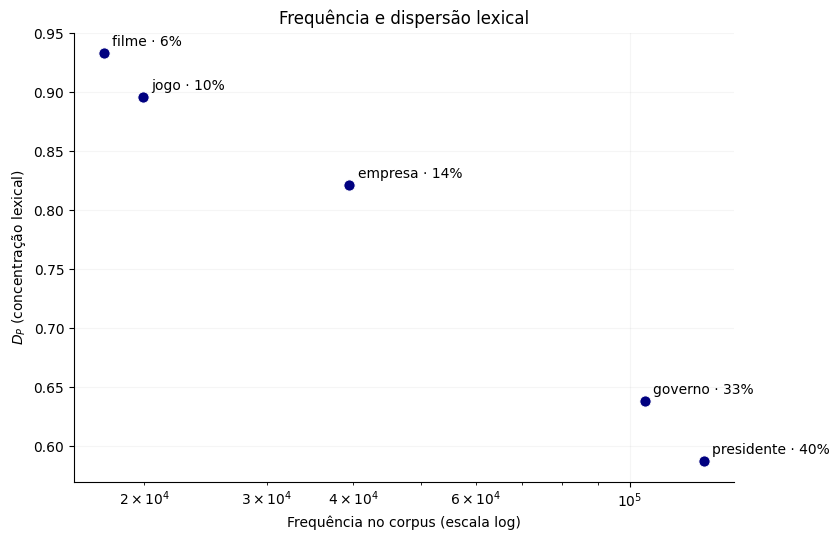

In [16]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))

# Plota os pontos relacionando frequência (eixo x) e dispersão DP (eixo y).
sns.scatterplot(
    data=resumo_lexical,
    x="frequencia",
    y="DP",
    s=65,
    color="navy",
    ax=ax,
)

# Percorre cada linha da tabela resumo para adicionar um rótulo de texto ao lado de cada ponto.
# Como o índice de 'resumo_lexical' são os próprios termos, 'termo' recebe o nome da palavra.
for termo, linha in resumo_lexical.iterrows():
    cobertura_pct = linha["cobertura_documental"] * 100

    ax.annotate(
        text=f"{termo} · {cobertura_pct:.0f}%",
        xy=(linha["frequencia"], linha["DP"]),
        xytext=(6, 5),
        textcoords="offset points",
        fontsize=10,
    )

# Transforma o eixo horizontal em escala logarítmica (base 10) para acomodar grandes diferenças de contagem.
ax.set_xscale("log")

ax.set(
    title="Frequência e dispersão lexical",
    xlabel="Frequência no corpus (escala log)",
    ylabel=r"$D_P$ (concentração lexical)",
)

ax.grid(alpha=0.12, linewidth=0.8)
ax.set_axisbelow(True)

sns.despine()
plt.tight_layout()
plt.show()


## 4. Anotação linguística com spaCy

Vamos acrescentar aos textos informações produzidas por um pipeline de
**processamento de linguagem natural (PLN)**. O spaCy combina segmentação em
tokens e componentes que atribuem anotações, como lemas, classes gramaticais,
relações de dependência, limites de sentenças e entidades nomeadas.

Usaremos `pt_core_news_sm`, um pipeline pré-treinado para português. Seus
componentes aprendidos produzem previsões a partir de dados de treinamento;
a inspeção de exemplos permitirá avaliar como essas previsões se comportam
no nosso corpus.

A célula seguinte baixará o modelo. Depois de carregá-lo com `spacy.load()`,
processaremos uma matéria e examinaremos suas anotações antes de construir
medidas para a amostra. A [documentação do pipeline de português](https://spacy.io/models/pt)
informa seus componentes, rótulos e fontes de treinamento.


In [17]:
!python -m spacy download pt_core_news_sm -q

✔ Download and installation successful
You can now load the package via spacy.load('pt_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [18]:
import spacy

# Carrega o modelo de processamento de português na memória.
# Este objeto (nlp) será responsável por tokenizar, analisar e anotar os textos do corpus.
nlp = spacy.load("pt_core_news_sm")


### 4.1 Processamento de uma matéria

Selecionaremos aleatoriamente uma matéria de `poder` com mais de 300 segmentos
em `n_palavras`.

A chamada `nlp(exemplo["texto"])` processará o texto completo e retornará um
objeto `Doc`. Esse objeto permite percorrer os tokens e consultar as anotações
associadas ao documento. A impressão ficará limitada aos primeiros mil
caracteres para facilitar a leitura; o processamento usará a matéria inteira.


In [19]:
# Filtra uma matéria longa da seção 'poder' para servir de exemplo pedagógico.
exemplo = (
    corpus_df
    .query("categoria == 'poder' and n_palavras > 300")
    .sample(n=1, random_state=42)
    .iloc[0]
)

print(exemplo["titulo"])
print()
print(exemplo["texto"][:1000])  # Exibe os primeiros 1000 caracteres do texto

# Processa o texto completo com o spaCy, gerando o objeto Doc estruturado.
doc = nlp(exemplo["texto"])

CPI vai convocar advogada para saber quem a ameaçou, diz Hugo Motta

O presidente da CPI da Petrobras, deputado Hugo Motta (PMDB-PB), afirmou nesta sexta-feira (31) que a convocação da advogada Beatriz Catta Preta está mantida e que a CPI quer saber quem a ameaçou.  Motta lançou suspeitas de que Catta Preta esteja se "vitimizando" para esconder "talvez alguns atos ilícitos que ela tenha cometido no âmbito do processo da Lava Jato".  Responsável por firmar nove acordos de delação premiada de réus da Operação Lava Jato, a advogada disse ao "Jornal Nacional" nesta quinta-feira (30) que deixou o caso e decidiu abandonar a advocacia porque se sentiu ameaçada.  "Depois de tudo que está acontecendo, e por zelar pela minha segurança e dos meus filhos, decidi encerrar minha carreira", afirmou.  Segundo ela, a pressão aumentou após um de seus clientes, o lobista Julio Camargo, mencionar em depoimento que pagou US$ 5 milhões em propina ao presidente da Câmara dos Deputados, Eduardo Cunha (PMDB-RJ

### 4.2 Tokens, lemas e dependências

Para cada token, consultaremos quatro atributos:

- `text`: sequência de caracteres que constitui o token;
- `lemma_`: lema atribuído pelo modelo;
- `pos_`: classe gramatical ampla, como `NOUN`, `PROPN`, `VERB` ou `ADJ`;
- `dep_`: rótulo da relação de dependência sintática.

O **lema** é a forma usada para representar um conjunto de formas flexionadas.
No exemplo, `afirmou` recebe o lema `afirmar`. Sua forma e suas
convenções dependem do anotador; o lema atribuído a `da` aparece como `de o`.
Esses exemplos ajudam a distinguir lematização de segmentação em raízes ou
morfemas.

Os rótulos de dependência descrevem relações na análise sintática produzida pelo
pipeline. `nsubj`, por exemplo, identifica uma relação de sujeito nominal, e
`ROOT` identifica a raiz da análise. A tabela mostrará os primeiros vinte
tokens após a exclusão dos tokens de espaço; pontuação e números continuarão
visíveis. As definições dos atributos estão na [API de Token](https://spacy.io/api/token).


In [20]:
pd.DataFrame(
    {
        "token": [
            token.text
            for token in doc
            if not token.is_space
        ],
        "lema": [
            token.lemma_
            for token in doc
            if not token.is_space
        ],
        "classe_gramatical": [
            token.pos_
            for token in doc
            if not token.is_space
        ],
        "dependencia": [
            token.dep_
            for token in doc
            if not token.is_space
        ],
    }
).head(20)

,token,lema,classe_gramatical,dependencia
0,O,o,DET,det
1,presidente,presidente,NOUN,nsubj
2,da,de o,ADP,case
3,CPI,CPI,PROPN,nmod
4,da,de o,ADP,case
5,Petrobras,Petrobras,PROPN,nmod
6,",",",",PUNCT,punct
7,deputado,deputado,NOUN,appos
8,Hugo,Hugo,PROPN,appos
9,Motta,Motta,PROPN,flat:name


### 4.3 Entidades nomeadas e inspeção das previsões

O reconhecimento de entidades identifica trechos do texto e atribui rótulos a
eles. O pipeline de português usado aqui dispõe de quatro rótulos: `PER`
(pessoa), `ORG` (organização), `LOC` (local) e `MISC` (outros tipos previstos
pelo esquema de anotação).

Cada elemento de `doc.ents` representa uma ocorrência anotada, que pode abranger
vários tokens. Consultaremos seu texto com `text` e seu rótulo com `label_`.

A tabela também permite observar erros: `decidi` foi classificado como
`PER`, e `US$`, como `LOC`. Ao construir medidas a partir dessas anotações,
estaremos incorporando o comportamento do modelo. A inspeção desses casos
ajuda a avaliar o significado das contagens e a planejar uma eventual revisão
manual das previsões.


In [21]:
pd.DataFrame(
    {
        "entidade": [
            entidade.text
            for entidade in doc.ents
        ],
        "rotulo": [
            entidade.label_
            for entidade in doc.ents
        ],
    }
).head(20)

,entidade,rotulo
0,Petrobras,ORG
1,Hugo Motta,PER
2,PMDB-PB,ORG
3,Beatriz Catta Preta,PER
4,Motta,PER
5,Catta Preta,ORG
6,Lava Jato,PER
7,Operação Lava Jato,MISC
8,Jornal Nacional,MISC
9,decidi,PER


### 4.4 Amostragem e definição das características

Para limitar o custo de anotação e manter o mesmo número de textos por seção,
coletaremos **500 matérias de cada categoria**, totalizando **3.500 documentos**.
Essa amostra estratificada dá igual representação às sete seções na etapa de
PLN, enquanto o corpus anterior preservava suas diferenças de tamanho.

O método `nlp.pipe()` processará os textos em lotes de 32. A chamada a `list()`
armazenará os documentos anotados, que serão percorridos para calcular cinco
características por matéria:

- **Comprimento médio das sentenças:** número de tokens dividido pelo número
  de sentenças identificadas pelo pipeline.
- **Proporção de nomes próprios:** tokens com `pos_ == "PROPN"` divididos pelo
  total de tokens considerado.
- **Proporção de adjetivos:** tokens com `pos_ == "ADJ"` divididos pelo mesmo
  denominador.
- **Proporção de verbos:** tokens com `pos_ == "VERB"` divididos pelo mesmo
  denominador. Os tokens classificados como `AUX` constituem uma classe separada.
- **Densidade de entidades:** número de ocorrências em `doc.ents` dividido pelo
  total de tokens considerado.

Na função abaixo, o denominador inclui todos os tokens do spaCy com
`is_space == False`, inclusive pontuação e números. A densidade conta ocorrências
de entidades, que podem ter vários tokens; uma entidade repetida contribui a
cada ocorrência reconhecida. Esses critérios devem acompanhar a interpretação
das proporções.

O cálculo pressupõe documentos com tokens e sentenças. Ao concatenar as medidas
com `nlp_df`, preservaremos a ordem dos textos para associar cada linha às
características extraídas de seu documento.


In [22]:
# Amostra exatamente 500 matérias de cada uma das 7 seções selecionadas,
# garantindo um corpus balanceado de 3.500 documentos.
nlp_df = (
    corpus_df
    .groupby("categoria", group_keys=False)
    .sample(n=500, random_state=42)
    .reset_index(drop=True)
)

# O nlp.pipe() processa os textos em fluxo contínuo (streaming) utilizando lotes (batch_size=32),
# o que otimiza o uso de memória e acelera drasticamente a anotação de milhares de documentos.
documentos = list(
    nlp.pipe(
        nlp_df["texto"],
        batch_size=32,
    )
)


def extrair_caracteristicas(doc):
    """Extrai métricas linguísticas estruturais de um objeto Doc do spaCy."""
    # Filtra apenas os tokens que não são espaços em branco
    tokens = [token for token in doc if not token.is_space]

    # Extrai as sentenças segmentadas pelo modelo
    sentencas = list(doc.sents)

    return {
        "comprimento_medio_sentenca": len(tokens) / len(sentencas),
        "proporcao_nomes_proprios": sum(token.pos_ == "PROPN" for token in tokens) / len(tokens),
        "proporcao_adjetivos": sum(token.pos_ == "ADJ" for token in tokens) / len(tokens),
        "proporcao_verbos": sum(token.pos_ == "VERB" for token in tokens) / len(tokens),
        "densidade_entidades": len(doc.ents) / len(tokens),
    }


# Aplica a função de extração a cada documento anotado gerando uma lista de dicionários,
# que é convertida diretamente em um DataFrame do Pandas.
caracteristicas = pd.DataFrame([extrair_caracteristicas(doc) for doc in documentos])

# Junta as novas colunas numéricas ao DataFrame principal da amostra via concatenação por colunas (axis=1).
nlp_df = pd.concat([nlp_df, caracteristicas], axis=1)

nlp_df.head()

,titulo,texto,data,categoria,subcategoria,link,n_palavras,governo,empresa,jogo,filme,presidente,n_tokens,comprimento_medio_sentenca,proporcao_nomes_proprios,proporcao_adjetivos,proporcao_verbos,densidade_entidades
0,Janot tem duas semanas para procurar flecha qu...,O procurador-geral Rodrigo Janot tem as próxim...,2017-03-09,colunas,eliogaspari,http://www1.folha.uol.com.br/colunas/eliogaspa...,275.0,0,0,0,0,0,279,16.888889,0.088816,0.059211,0.128289,0.065789
1,A melhor coisa do avião é o que ele (ainda) nã...,"Nunca tive medo de avião, mas o contrário diss...",2017-05-29,colunas,gregorioduvivier,http://www1.folha.uol.com.br/colunas/gregoriod...,419.0,0,0,0,0,0,424,18.222222,0.020325,0.044715,0.138211,0.020325
2,É hora de minha geração ocupar os espaços de p...,"Luciano Huck, 45, colocou blazer para gravar o...",2017-03-30,colunas,redesocial,http://www1.folha.uol.com.br/colunas/redesocia...,1746.0,0,0,0,2,3,1747,13.414474,0.043649,0.049534,0.124571,0.037273
3,Dilma mostra resignação com ideia de que seu g...,A presidente Dilma Rousseff já reage com resig...,2016-11-03,colunas,monicabergamo,http://www1.folha.uol.com.br/colunas/monicaber...,716.0,3,0,0,0,6,719,17.666667,0.179245,0.027123,0.087264,0.097877
4,"Colheita atrasa, e exportação de soja tem qued...",As exportações de soja estão com um ritmo bem ...,2015-03-24,colunas,vaivem,http://www1.folha.uol.com.br/colunas/vaivem/20...,644.0,0,2,0,0,0,658,20.472222,0.058345,0.055631,0.077341,0.043419


## 5. Comparação das características entre seções

Começaremos pelas médias das cinco características em cada seção. Cada valor
será a média dos resultados calculados **por matéria**, atribuindo o mesmo peso
aos 500 documentos daquele grupo. Por exemplo, a média das proporções de verbos
por matéria pode diferir de uma proporção obtida ao reunir todos os tokens da
seção em um único total.

Nas médias calculadas, `mercado` apresenta o maior comprimento médio das sentenças
(23,860 tokens), enquanto `ilustrissima` apresenta a maior proporção média de
adjetivos (0,060). Usaremos esses resumos junto às distribuições e aos testes
para examinar os contrastes observados.


In [23]:
# Define a lista com os nomes das colunas de interesse geradas pela anotação do spaCy.
caracteristicas_linguisticas = [
    "comprimento_medio_sentenca",
    "proporcao_nomes_proprios",
    "proporcao_adjetivos",
    "proporcao_verbos",
    "densidade_entidades",
]

# Agrupa a amostra por categoria, calcula a média de cada característica e arredonda para 3 casas decimais.
(
    nlp_df
    .groupby("categoria")[caracteristicas_linguisticas]
    .mean()
    .round(3)
)


,comprimento_medio_sentenca,proporcao_nomes_proprios,proporcao_adjetivos,proporcao_verbos,densidade_entidades
categoria,,,,,
colunas,19.881,0.077,0.054,0.106,0.052
esporte,20.347,0.136,0.044,0.092,0.085
ilustrada,19.641,0.129,0.049,0.093,0.068
ilustrissima,20.774,0.104,0.060,0.092,0.056
mercado,23.860,0.075,0.051,0.097,0.055
mundo,22.866,0.091,0.052,0.104,0.062
poder,23.298,0.114,0.039,0.104,0.076


### 5.1 Distribuição do comprimento médio das sentenças

Vamos comparar `colunas` e `ilustrissima` quanto ao comprimento médio das
sentenças. Cada observação do histograma representará uma **matéria**, resumida
pelo número médio de tokens por sentença produzido pela função anterior.

Com `stat="density"` e `common_norm=False`, cada distribuição terá área total
igual a 1. O eixo vertical expressará densidade, e a largura dos intervalos
participará dessa normalização. As alturas das barras permitem comparar a
forma das distribuições na escala comum dos dois grupos.

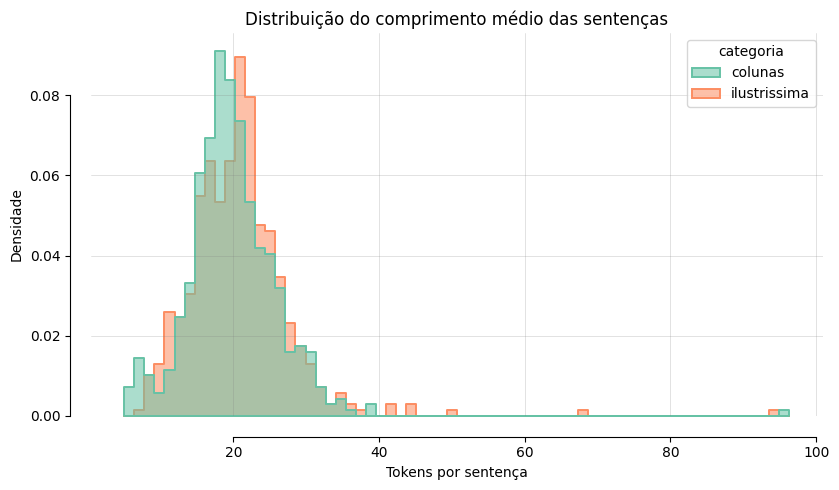

In [24]:
comparacao_df = nlp_df.query(
    "categoria in ['colunas', 'ilustrissima']"
)

fig, ax = plt.subplots(figsize=(8.5, 5))

sns.histplot(
    data=comparacao_df,
    x="comprimento_medio_sentenca",
    hue="categoria",
    hue_order=["colunas", "ilustrissima"],
    palette="Set2",
    bins="fd",
    stat="density",
    common_norm=False,
    element="step",
    fill=True,
    alpha=0.55,
    linewidth=1.4,
    ax=ax,
)

ax.set(
    title="Distribuição do comprimento médio das sentenças",
    xlabel="Tokens por sentença",
    ylabel="Densidade",
)

ax.grid(
    True,
    alpha=0.4,
    linewidth=0.4,
    color="grey",
)

sns.despine(ax=ax, top=True, trim=True, offset=15)
plt.tight_layout()
plt.show()

### 5.2 Diferença entre as médias amostrais

Definiremos a estatística como a média de `colunas` menos a média de
`ilustrissima`:

$$
\Delta = \bar{x}_{\text{colunas}} - \bar{x}_{\text{ilustrissima}}.
$$

A ordem da subtração fixa a interpretação do sinal. No resultado,
$\Delta \approx -0{,}892$: a média dos comprimentos médios de sentença das
matérias de `colunas` fica aproximadamente 0,892 token por sentença abaixo da
de `ilustrissima`.

Essa diferença resume a magnitude do contraste na escala da medida.

In [25]:
colunas = nlp_df.query(
    "categoria == 'colunas'"
)["comprimento_medio_sentenca"]

ilustrissima = nlp_df.query(
    "categoria == 'ilustrissima'"
)["comprimento_medio_sentenca"]

diferenca_observada = (
    colunas.mean()
    - ilustrissima.mean()
)

diferenca_observada

np.float64(-0.8924414527693969)

### 5.3 Teste de permutação para dois grupos

O teste de permutação independente parte de uma hipótese nula sob a qual os
valores vêm de uma **distribuição comum** e seus rótulos de seção são
permutáveis. Sob essa hipótese, redistribuir as observações entre os grupos,
preservando seus tamanhos, produz novas diferenças de médias compatíveis com
o modelo de referência.

Construiremos a distribuição de permutação em três etapas:

1. Reunir os valores dos dois grupos e redistribuí-los aleatoriamente entre
   `colunas` e `ilustrissima`, mantendo 500 observações em cada grupo.
2. Calcular a diferença de médias em cada redistribuição.
3. Repetir o procedimento 19.999 vezes e comparar a estatística observada com
   essa distribuição.

A diferença de médias focaliza o contraste de localização, e
`alternative="two-sided"` considera desvios em ambas as direções. O argumento
`rng` controla a sequência aleatória usada pela função.

A validade da permutação depende da **permutabilidade das observações sob a
hipótese nula**. Em um corpus, autoria recorrente, matérias relacionadas ou
duplicações podem introduzir dependências que exigiriam um desenho de
reamostragem apropriado. Aqui, trataremos a matéria como unidade da comparação
exploratória. A [documentação do SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html)
descreve a hipótese associada à permutação independente e o cálculo do p-valor.


In [26]:
def diferenca_medias(x, y):
    """Função de cálculo da estatística de teste: diferença entre médias de dois arrays."""
    return np.mean(x) - np.mean(y)


# Executa o teste de permutação bicaudal (two-sided) com 19.999 reamostragens
resultado_permutacao = stats.permutation_test(
    data=(colunas, ilustrissima),
    statistic=diferenca_medias,
    alternative="two-sided",
    n_resamples=19_999,
    rng=np.random.default_rng(42),
)

### 5.4 Distribuição de permutação e p-valor

O histograma mostrará as diferenças de médias obtidas nas redistribuições dos
mesmos valores entre os grupos. A linha tracejada localizará a diferença
observada nos dados.

O **p-valor** quantifica a extremidade da estatística observada segundo essa
distribuição de referência. Para o teste bilateral, o SciPy calcula as
probabilidades nas duas caudas, dobra a menor delas e limita o resultado a 1.
Nas permutações aleatórias, acrescenta uma unidade ao numerador e ao denominador
da contagem de cauda. O resultado é uma aproximação de Monte Carlo à
probabilidade definida sob a hipótese nula.

A decisão será comparada a $\alpha = 0{,}05$. A interpretação reunirá o
p-valor, a diferença observada e as condições da comparação. O tamanho do
contraste continua expresso em tokens por sentença; o p-valor expressa sua
compatibilidade com a hipótese de referência.


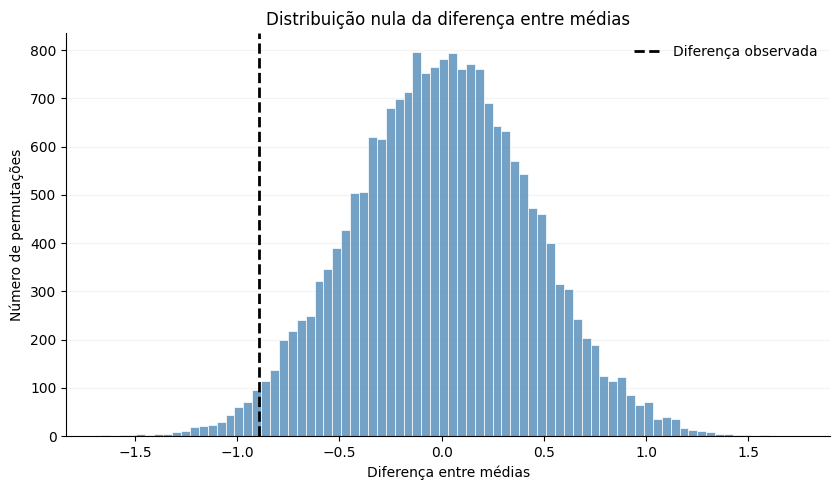

In [27]:
fig, ax = plt.subplots(figsize=(8.5, 5))

# Plota a distribuição nula obtida empiricamente pelas permutações
sns.histplot(
    resultado_permutacao.null_distribution,
    bins="fd",
    color="steelblue",
    edgecolor="white",
    linewidth=0.5,
    ax=ax,
)

# Adiciona uma linha vertical pontilhada indicando onde se posiciona a diferença observada real
ax.axvline(
    diferenca_observada,
    color="black",
    linestyle="--",
    linewidth=2,
    label="Diferença observada",
)

ax.set(
    title="Distribuição nula da diferença entre médias",
    xlabel="Diferença entre médias",
    ylabel="Número de permutações",
)

ax.grid(axis="y", alpha=0.15, linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False)

sns.despine()
plt.tight_layout()
plt.show()


In [28]:
alpha = 0.05

print(f"Diferença observada: {diferenca_observada:.3f}")
print(f"P-valor: {resultado_permutacao.pvalue:.4f}")
print(f"Nível de significância (alpha): {alpha}")

if resultado_permutacao.pvalue < alpha:
    print("Como o p-valor é menor que alpha, rejeitamos a hipótese nula.")
else:
    print("Como o p-valor é maior ou igual a alpha, não há evidências suficientes para rejeitar a hipótese nula.")


Diferença observada: -0.892
P-valor: 0.0391
Nível de significância (alpha): 0.05
Como o p-valor é menor que alpha, rejeitamos a hipótese nula.


Na saída salva, a diferença é de aproximadamente $-0{,}892$ token por sentença,
com $p=0{,}0391$. Pelo critério de 5%, rejeitamos a hipótese nula nessa comparação
exploratória, sob as condições do procedimento. A interpretação substantiva
deve considerar que o contraste entre as médias é inferior a um token por
sentença, além da dispersão e da sobreposição observadas no histograma.


### 5.5 Testes globais para as sete seções

Vamos ampliar a comparação para as sete seções, avaliando cada uma das cinco
características separadamente. Para cada característica, usaremos a
**estatística $F$ da ANOVA de um fator** como resumo do contraste entre os grupos.

A estatística relaciona dois quadrados médios, isto é, duas somas de quadrados
divididas pelos respectivos graus de liberdade:

$$
F = \frac{MS_{\text{entre}}}{MS_{\text{dentro}}}.
$$

O numerador resume o afastamento das médias dos grupos em relação à média
geral, ponderado pelo tamanho de cada grupo e dividido por $k-1$. O denominador
resume o afastamento das observações em relação à média de seu próprio grupo,
dividido por $N-k$. Aqui, $k=7$ seções e $N=3\,500$ matérias.

Valores elevados de $F$ indicam maior separação entre as médias relativamente à
variabilidade interna. Essa direção define a cauda de interesse do teste:

$$
P\left(F_{\text{permutado}} \geq F_{\text{observado}}\mid H_0\right).
$$

Usaremos `f_oneway()` para calcular a estatística e `permutation_test()` para
obter sua distribuição de referência. A cada redistribuição, os grupos
conservarão seus tamanhos; `alternative="greater"` selecionará a cauda direita.
A inferência seguirá as condições de permutabilidade discutidas na comparação
anterior, com a hipótese nula de uma distribuição comum entre as seções para
cada característica.

Cada elemento de `grupos` terá 500 linhas e cinco colunas. Com `axis=0`, a
estatística será calculada ao longo das matérias, produzindo um resultado por
coluna. `vectorized=True` permitirá calcular vários resultados em uma chamada,
e `batch=1_000` limitará o número de redistribuições processadas por lote.


In [29]:
def estatistica_f(*grupos, axis=0):
    """Calcula apenas a estatística F (ANOVA) entre múltiplos grupos."""
    # O operador * (empacotamento/desempacotamento) permite que a função receba
    # um número arbitrário de grupos (neste caso, as 7 seções) e os repasse
    # diretamente como argumentos separados para stats.f_oneway().
    resultado_anova = stats.f_oneway(
        *grupos,
        axis=axis,  # Eixo ao longo do qual as amostras são comparadas
    )

    # Extraímos apenas o atributo .statistic (ignorando o valor-p paramétrico),
    # pois o valor-p será calculado empiricamente pelo teste de permutação.
    return resultado_anova.statistic


In [30]:
# Construímos uma lista de arrays NumPy: um para cada seção do corpus.
# Converter cada subconjunto com .to_numpy() acelera as milhares de
# reamostragens que o SciPy fará na etapa seguinte.
grupos = [
    nlp_df.loc[
        nlp_df["categoria"].eq(categoria),  # Filtra as linhas da seção atual
        caracteristicas_linguisticas,       # Seleciona a(s) coluna(s) de interesse
    ].to_numpy()
    for categoria in categorias_selecionadas
]


In [31]:
resultado_global = stats.permutation_test(
    data=tuple(grupos),
    statistic=estatistica_f,
    permutation_type="independent",
    vectorized=True,
    axis=0,
    alternative="greater",
    n_resamples=19_999,
    batch=1_000,
    rng=np.random.default_rng(42),
)


### 5.6 Estatísticas e valores-p dos testes globais

O DataFrame `testes_globais` reunirá uma estatística $F$ e um valor-p para cada
característica. A vetorização torna o cálculo conjunto mais eficiente, mas a
estrutura inferencial continua sendo uma família de **cinco testes**, cada um
referente a uma variável.

Aqui, todos os p-valores são 0,00005. Com 19.999 permutações aleatórias
e a correção de uma unidade usada pelo SciPy, esse é o menor valor possível
para a cauda direita: $1/(19\,999+1)$. Os cinco resultados atingiram, portanto,
o limite de resolução desta execução.


In [32]:
testes_globais = pd.DataFrame(
    {
        "caracteristica": caracteristicas_linguisticas,
        "estatistica_f": resultado_global.statistic,
        "p_valor": resultado_global.pvalue,
    }
)

testes_globais

,caracteristica,estatistica_f,p_valor
0,comprimento_medio_sentenca,44.331637,0.00005
1,proporcao_nomes_proprios,79.776006,0.00005
2,proporcao_adjetivos,67.918784,0.00005
3,proporcao_verbos,38.480210,0.00005
4,densidade_entidades,85.638662,0.00005


### 5.7 Ajuste de Holm para os cinco testes

Ao tomar decisões sobre cinco hipóteses, precisamos considerar a possibilidade
de ao menos uma rejeição incorreta na família. O procedimento de **Holm**
controla essa taxa de erro familiar (*family-wise error rate*, FWER) no nível
escolhido, desde que os valores-p de entrada sejam válidos para seus testes.

Aplicaremos `multipletests()` com `method="holm"` e $\alpha=0{,}05$. A função
retornará os valores-p ajustados e as decisões de rejeição. A documentação de
[`multipletests()`](https://www.statsmodels.org/stable/generated/statsmodels.stats.multitest.multipletests.html)
descreve seus argumentos e retornos.

A família definida nesta etapa contém os cinco testes globais. A comparação
anterior entre `colunas` e `ilustrissima` foi usada como exploração de dois
grupos e permanece fora desse ajuste. Uma análise confirmatória que reunisse
ambas as etapas precisaria definir e justificar a família de hipóteses
correspondente.


In [36]:
from statsmodels.stats.multitest import multipletests

# Aplica a correção de Holm para o conjunto de valores-p obtidos nos testes globais
rejeita_h0, p_valores_holm, _, _ = multipletests(
    testes_globais["p_valor"],
    alpha=alpha,
    method="holm",
)

# Adiciona os resultados corrigidos ao DataFrame de testes
testes_globais["p_valor_holm"] = p_valores_holm
testes_globais["rejeita_h0"] = rejeita_h0

testes_globais

,caracteristica,estatistica_f,p_valor,p-valor_holm,rejeita_h0,p_valor_holm
0,comprimento_medio_sentenca,44.331637,0.00005,0.00025,True,0.00025
1,proporcao_nomes_proprios,79.776006,0.00005,0.00025,True,0.00025
2,proporcao_adjetivos,67.918784,0.00005,0.00025,True,0.00025
3,proporcao_verbos,38.480210,0.00005,0.00025,True,0.00025
4,densidade_entidades,85.638662,0.00005,0.00025,True,0.00025


### 5.8 Interpretação dos testes globais

Na tabela ajustada, os cinco valores-p são 0,00025, e `rejeita_h0` é
`True` para todas as características. Sob as condições de permutação adotadas,
os resultados fornecem evidência de diferenças entre seções nos contrastes
resumidos pela estatística $F$.

O alcance de cada teste é global. Para localizar os contrastes, seria necessário
examinar comparações específicas com um plano de inferência adequado. A
interpretação linguística também deve retomar as médias, as distribuições e a
qualidade das anotações que produziram as medidas.

Como as seções constituem grupos observacionais, a análise descreve associações
entre categoria editorial e características dos textos. Atribuir essas
diferenças a causas específicas exigiria um desenho que considerasse fatores
como assunto, autoria e período de publicação.

A chamada a `round(4)` na próxima célula arredondará os valores-p brutos para
`0.0`. Esse resultado pertence à apresentação numérica; os valores mantidos em
`testes_globais` continuam positivos. Para relatá-los, usaremos a precisão da
tabela anterior ou notação científica.


In [37]:
(
    testes_globais
    .sort_values("p_valor_holm")
    .round(4)
)

,caracteristica,estatistica_f,p_valor,p-valor_holm,rejeita_h0,p_valor_holm
0,comprimento_medio_sentenca,44.3316,0.0,0.0002,True,0.0002
1,proporcao_nomes_proprios,79.7760,0.0,0.0002,True,0.0002
2,proporcao_adjetivos,67.9188,0.0,0.0002,True,0.0002
3,proporcao_verbos,38.4802,0.0,0.0002,True,0.0002
4,densidade_entidades,85.6387,0.0,0.0002,True,0.0002


### 5.9 Comparação das estatísticas F

O gráfico seguinte mostrará os valores de $F$ para as cinco características.
Cada barra representa a razão entre o quadrado médio entre seções e o quadrado
médio dentro delas, para aquela variável.

Esse resumo permite observar quais contrastes apresentam maior separação
relativa à variabilidade interna. A avaliação de magnitude linguística deve
retornar à escala de cada medida: tokens por sentença, proporções de classes
gramaticais e ocorrências de entidades por token. O valor de $F$ integra essa
leitura com as médias e distribuições dos grupos.


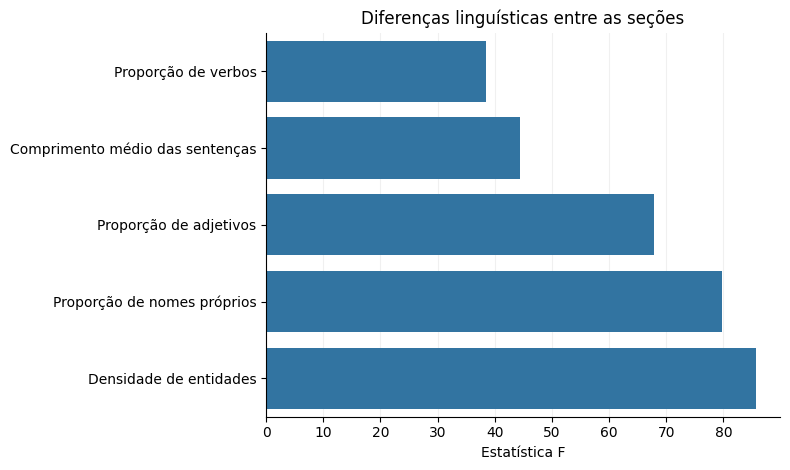

In [38]:
rotulos_caracteristicas = {
    "comprimento_medio_sentenca": "Comprimento médio das sentenças",
    "proporcao_nomes_proprios": "Proporção de nomes próprios",
    "proporcao_adjetivos": "Proporção de adjetivos",
    "proporcao_verbos": "Proporção de verbos",
    "densidade_entidades": "Densidade de entidades",
}

plot_df = (
    testes_globais
    .assign(
        caracteristica=lambda df:
            df["caracteristica"].map(rotulos_caracteristicas)
    )
    .sort_values("estatistica_f")
)

fig, ax = plt.subplots(figsize=(8, 4.8))

sns.barplot(
    data=plot_df,
    x="estatistica_f",
    y="caracteristica",
    ax=ax,
)

ax.set(
    title="Diferenças linguísticas entre as seções",
    xlabel="Estatística F",
    ylabel="",
)

ax.grid(
    axis="x",
    alpha=0.18,
    linewidth=0.8,
)

ax.set_axisbelow(True)

sns.despine()
plt.tight_layout()
plt.show()

## 6. Visualização com Clusters (PCA)

As cinco características também podem ser examinadas em conjunto. A **análise
de componentes principais (PCA)** construirá combinações lineares das variáveis
para representar parte de sua variação em um plano.

Primeiro, `StandardScaler()` centralizará cada característica e a dividirá por
seu desvio-padrão. A padronização dará uma escala comum ao comprimento médio
das sentenças e às proporções. Em seguida, `PCA(n_components=2)` calculará duas
direções ortogonais: a primeira maximiza a variância das projeções, e a segunda
maximiza a variância restante sob a condição de ortogonalidade.

O ajuste usará apenas as cinco características numéricas. A coluna `categoria`
será retomada depois, para organizar os painéis e as cores. Essa é uma aplicação
exploratória de aprendizagem não supervisionada: o modelo constrói a projeção
a partir das relações entre as medidas.

### 6.1 Construção e leitura dos painéis

Cada matéria receberá duas coordenadas, `cp1` e `cp2`. Em cada painel, os pontos
cinza representarão a amostra completa, os contornos coloridos mostrarão uma
estimativa de densidade da seção destacada e o marcador com borda indicará sua
posição média no plano, o **centroide**.

Os painéis compartilharão os mesmos limites, definidos pelos quantis de 2% e
98% de cada componente. Essa escolha focaliza a região central da projeção;
as observações além dos limites continuam participando do ajuste e do cálculo
dos centroides. A ordem dos painéis seguirá a coordenada média no primeiro
componente.

As áreas coloridas representam densidades estimadas, cuja forma depende da
suavização usada pelo gráfico. A sobreposição permite examinar semelhanças e
diferenças na projeção das características selecionadas.


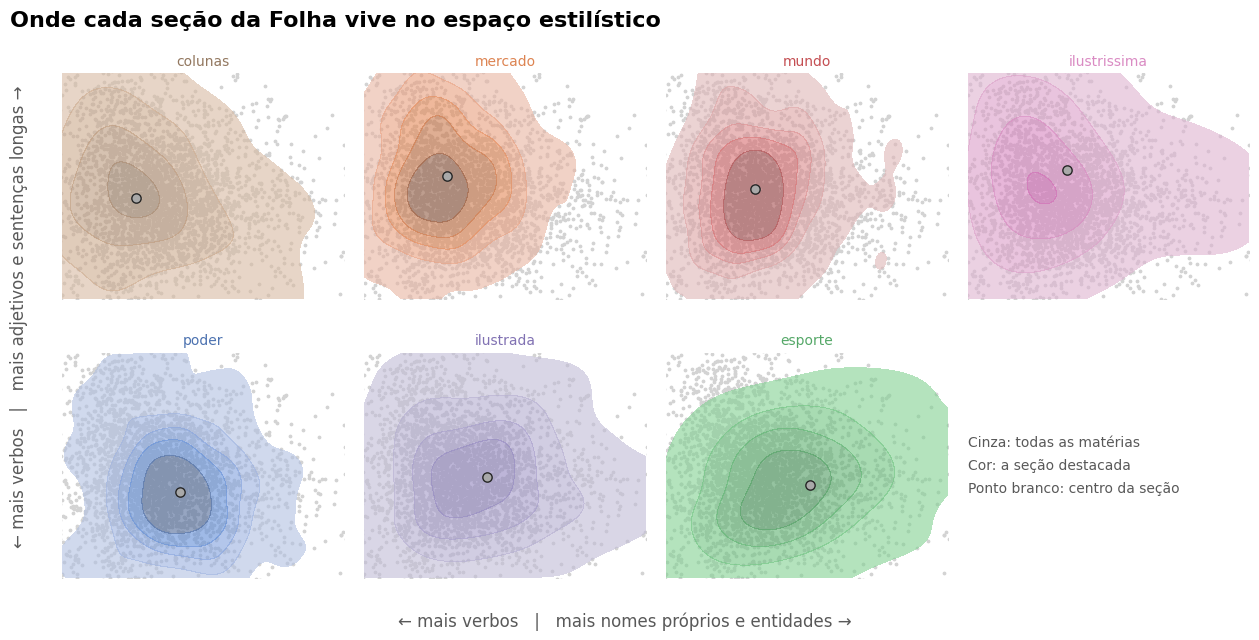

In [41]:
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# 1. PCA: padroniza as cinco características e projeta em duas dimensões.
modelo_pca = make_pipeline(
    StandardScaler(),
    PCA(n_components=2),
)

dados_pca = nlp_df.dropna(subset=caracteristicas_linguisticas)

componentes = modelo_pca.fit_transform(dados_pca[caracteristicas_linguisticas])

pca = modelo_pca.named_steps["pca"]

pca_df = dados_pca[["categoria"]].assign(cp1=componentes[:, 0], cp2=componentes[:, 1])

centroides = pca_df.groupby("categoria")[["cp1", "cp2"]].mean()

ordem_paineis = centroides.sort_values("cp1").index

# 2. Um painel por seção, ordenados pela posição no componente 1.
g = sns.displot(
    data=pca_df,
    x="cp1",
    y="cp2",
    col="categoria",
    col_wrap=4,
    col_order=ordem_paineis,
    hue="categoria",
    palette=paleta_categorias,
    legend=False,
    kind="kde",
    fill=True,
    levels=6,
    thresh=0.05,
    alpha=0.6,
    height=3.2,
    facet_kws={
        "xlim": tuple(pca_df["cp1"].quantile([0.02, 0.98])),
        "ylim": tuple(pca_df["cp2"].quantile([0.02, 0.98])),
    },
)
g.set_titles("{col_name}")

g.set(
    xticks=[],
    yticks=[],
    xlabel="",
    ylabel="",
)

g.despine(left=True, bottom=True)

# 3. Em cada painel: corpus completo em cinza e o centro da seção.
for categoria, ax in g.axes_dict.items():
    ax.scatter(
        pca_df["cp1"],
        pca_df["cp2"],
        s=3,
        color="lightgrey",
        zorder=0,
        rasterized=True,
    )
    ax.scatter(
        *centroides.loc[categoria],
        s=45,
        color="darkgrey",
        edgecolor="0.15",
        zorder=5,
    )

    ax.title.set_color(paleta_categorias[categoria])

# 4. Oitavo espaço da grade: guia de leitura em texto.
ax = g.figure.add_subplot(2, 4, 8)

ax.axis("off")

ax.text(
    0, 0.5,
    "Cinza: todas as matérias\nCor: a seção destacada\nPonto branco: centro da seção",
    va="center",
    fontsize=10,
    color="0.35",
    linespacing=1.8,
)

# 5. Títulos e eixos interpretativos (conferir com a tabela de cargas).
g.figure.suptitle(
    "Onde cada seção da Folha vive no espaço estilístico",
    x=0.02,
    ha="left",
    fontsize=16,
    fontweight="bold",
)
g.figure.supxlabel(
    "← mais verbos   |   mais nomes próprios e entidades →",
    color="0.35",
)

g.figure.supylabel(
    "← mais verbos   |   mais adjetivos e sentenças longas →",
    color="0.35",
)

g.figure.subplots_adjust(top=0.88)
plt.show()

### 6.2 Interpretação dos componentes

A interpretação linguística dos eixos depende dos coeficientes disponíveis
em `pca.components_`, na mesma ordem de `caracteristicas_linguisticas`. Eles
informam como cada variável padronizada participa das combinações lineares.
Já `pca.explained_variance_ratio_` informa a proporção da variância representada
por cada componente. A soma dos dois valores permite avaliar quanto da variação
das cinco medidas o plano preserva.

Os rótulos linguísticos acrescentados aos eixos do gráfico são propostas de
interpretação que precisam ser conferidas contra esses coeficientes. Essa
verificação deve acompanhar a leitura da direção de cada eixo, pois a
orientação dos componentes admite inversão de sinal. O marcador dos centroides
foi desenhado em cinza com borda escura; a expressão “ponto branco” na legenda
textual deve ser lida como referência a esse marcador.

A projeção oferece uma representação parcial dos perfis medidos. Sua leitura
deve considerar a variância preservada, a sobreposição entre seções, o critério
de amostragem e a qualidade da anotação automática. A [documentação de PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)
descreve os atributos usados nessa interpretação.


## 7. Síntese da análise

O percurso começou com registros de matérias e conservou essa unidade ao
construir medidas linguísticas. Na exploração lexical, as cinco formas
apresentaram diferenças de frequência, cobertura e dispersão: `presidente`
teve a maior cobertura documental, enquanto `filme` apresentou o maior $D_P$
entre os exemplos selecionados.

Na amostra balanceada de 3.500 textos, a anotação automática permitiu comparar
cinco características entre sete seções. Os testes globais produziram evidência
de diferenças nos contrastes resumidos por $F$, sob as condições de permutação
adotadas. A PCA reuniu as medidas em uma projeção exploratória, cuja
interpretação depende dos coeficientes e da variância preservada.

Cada resultado corresponde a escolhas de corpus, amostragem, segmentação,
anotação e medida. Explicitar essas escolhas permite relacionar o código à
pergunta linguística e avaliar o alcance das conclusões.
